In [28]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
from functools import partial

from cdrmip_extremes import (
    utils, processing, gwl
)
from cdrmip_extremes.utils import _map_leaves, reduce_member_tree
from cdrmip_extremes.configs import DATA_DIR, RAW_DIR, PROC_DIR, FIG_DIR, CDR_MODELS as models, CDR_EXPTS as expts

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [4]:
def load_mrsos(models=models):
    # load
    save_dir = RAW_DIR / 'mrsos'
    data = {model:{} for model in models}
    for expt in ['1pctCO2','1pctCO2-cdr']:
        expt_dir = save_dir / expt
        for model in models:
            path = expt_dir / f"{model}_{expt}_mrsos.nc"
            data[model][expt] = xr.open_dataarray(path,use_cftime=True)
    return data

In [6]:
data = load_mrsos()

In [7]:
crossing_years = utils.reduce_member_tree(
    io_disk.load_tree(PROC_DIR, 'crossing_years', 'CDRMIP', as_dataarray=True,model_order=models)
)

In [8]:
branch_date_overrides = {} 

expt = '1pctCO2-cdr'
concat = defaultdict(lambda: defaultdict(dict))
for model, expts in data.items():
    parent = expts.get('1pctCO2', {})
    ds = expts['1pctCO2-cdr']
    concat[model] = processing.concatenate_branches(
        ds, parent, branch_date=branch_date_overrides.get(model), realign_years = (0,140)
    ).assign_attrs(experiment_id=expt)

concat = utils.defaultdict_to_dict(concat)

Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-16 12:00:00, child relabeled to start 0140-01-16 12:00:00)
Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-16 12:00:00, child relabeled to start 0140-01-16 12:00:00)
Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-15 12:00:00, child relabeled to start 0140-01-15 11:45:00)
Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-16 12:00:00, child relabeled to start 0140-01-16 12:00:00)
Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-16 12:00:00, child relabeled to start 0140-01-16 12:00:00)
Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-16 12:00:00, child relabeled to start 0140-01-16 12:00:00)
Concatenating via realign_years=(0, 140) (parent relabeled to end 0139-12-16 12:00:00, child relabeled to start 0140-01-16 12:00:00)
Concatenating via realign_years=(0, 140) (parent relabeled to end 013

In [10]:
crossing_years

{'ACCESS-ESM1-5': {'1pctCO2-cdr': <xarray.DataArray 'crossing_years' (gwl: 1, branch: 2)> Size: 16B
  dask.array<median, shape=(1, 2), dtype=float64, chunksize=(1, 2), chunktype=numpy.ndarray>
  Coordinates:
    * gwl      (gwl) float64 8B 1.5
    * branch   (branch) <U9 72B 'ramp_up' 'ramp_down'},
 'CanESM5': {'1pctCO2-cdr': <xarray.DataArray 'crossing_years' (gwl: 1, branch: 2)> Size: 16B
  dask.array<median, shape=(1, 2), dtype=float64, chunksize=(1, 2), chunktype=numpy.ndarray>
  Coordinates:
    * gwl      (gwl) float64 8B 1.5
    * branch   (branch) <U9 72B 'ramp_up' 'ramp_down'},
 'CESM2': {'1pctCO2-cdr': <xarray.DataArray 'crossing_years' (gwl: 1, branch: 2)> Size: 16B
  dask.array<median, shape=(1, 2), dtype=float64, chunksize=(1, 2), chunktype=numpy.ndarray>
  Coordinates:
    * gwl      (gwl) float64 8B 1.5
    * branch   (branch) <U9 72B 'ramp_up' 'ramp_down'},
 'CNRM-ESM2-1': {'1pctCO2-cdr': <xarray.DataArray 'crossing_years' (gwl: 1, branch: 2)> Size: 16B
  dask.array<med

In [16]:
gwl_periods = {}
for model, ds in concat.items():
    gwl_years = crossing_years[model]['1pctCO2-cdr']
    gwl_periods[model] = gwl.extract_gwl_period(
        ds,
        gwl_years,
        window=21,
        time_dim='time'
    ).sel(gwl=1.5)

In [22]:
slices_15 = {
    model: gwl.gwl_branch_difference(gwl_periods[model],percent=True) for model in models
}

## Plot differences at 1.5ºC ##

In [24]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
import matplotlib.cm as cm
from matplotlib.colors import ListedColormap, BoundaryNorm

In [26]:
def plot_gwl_diff(to_plot,levels):

    cmap = plt.cm.RdYlBu_r.copy()
    # cmap.set_extremes(under='midnightblue',over='maroon')
          


    fig, axes = plt.subplots(2,4, subplot_kw={"projection":ccrs.Robinson()},
                         figsize=(17,6),
                         sharey=True,)

    cbar_kwargs = {"fraction": 0.02, "aspect": 20,
                    "label":"Soil Moisture Change",'orientation':'vertical',
                    'location':'right','pad':0.01,
                  'anchor':(0.5,-4), 'extend':'both'
                  }
 
    norm = BoundaryNorm(levels, ncolors=cmap.N, clip=True)
    
    for (model, da), ax in zip(to_plot.items(), axes.flat):
        im = ax.imshow(to_plot[model],
                       transform=ccrs.PlateCarree(),
                       cmap=cmap,
                       origin='lower',
                       extent=(0,360,-90,90),
                       norm=norm
                      )
        ax.set_title(model,fontsize=16)
        ax.coastlines()

    cbar_ax = fig.add_axes([1.01,0.05,0.01,0.8])
    cbar = fig.colorbar(im,
                        cax=cbar_ax,
                        **cbar_kwargs
                       )
    cbar.ax.tick_params(labelsize=14) 
    cbar.set_label("Relative Soil Moisture Difference (%)", fontsize=16)
    fig.suptitle(f"Top soil moisture difference ramp-down - ramp-up at 1.5°C GWL",
                 fontsize=25,
                 y=1.0
                )
    fig.tight_layout()
    plt.show()
    return fig

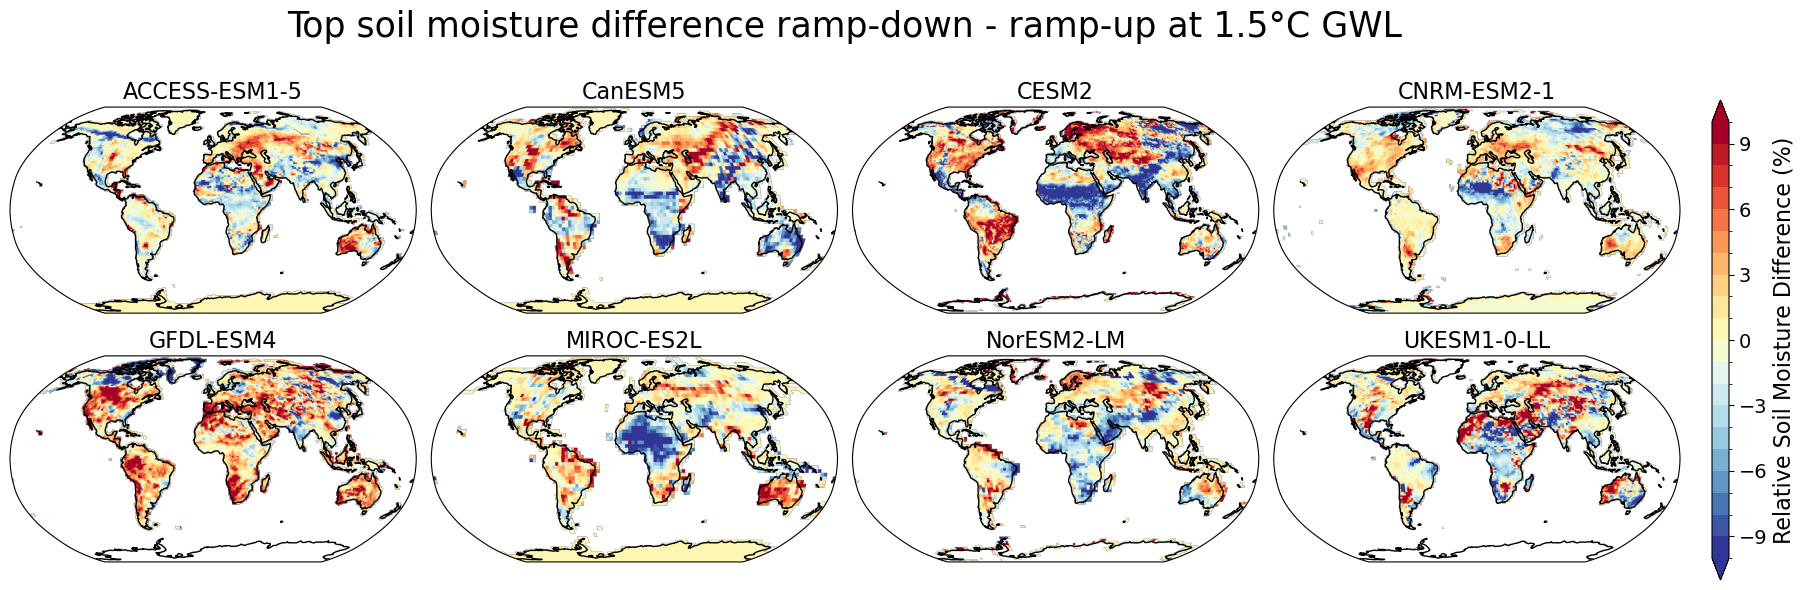

In [29]:
fig = plot_gwl_diff(
    slices_15,
    np.linspace(-10,10,21)
)

fig.savefig(
    FIG_DIR / "supplementary" / "figure_S29.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)